<a href="https://colab.research.google.com/github/smen0n/smen0n.github.io/blob/main/3/partb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [38]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [97]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
import copy
from tqdm.notebook import tqdm
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [40]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [41]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        # apply convolution
        self.net = nn.Sequential(nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),nn.BatchNorm2d(out_channels),nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),nn.BatchNorm2d(out_channels),nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1),nn.BatchNorm2d(out_channels),nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.pool = nn.AvgPool2d(kernel_size=7)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.pool(x)
        # ===== end of code ====
        #raise NotImplementedError()


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=1, padding=0),nn.BatchNorm2d(in_channels),nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(Conv(in_channels, out_channels),Conv(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(DownConv(in_channels, out_channels),ConvBlock(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.up = UpConv(in_channels, out_channels)
        self.conv = ConvBlock(out_channels, out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.up(x)
        return self.conv(x)
        # ===== end of code ====
        #raise NotImplementedError()

## Implementing Unconditional UNet

In [42]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        # encoder step:
        self.in_conv = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, 2 * D)
        self.down2 = DownBlock(2 * D, 4 * D)
        # latent vector step:
        self.flatten = Flatten()
        self.unflatten = Unflatten(4 * D)
        # decoder step:
        self.up1 = UpBlock(8 * D, 2 * D)
        self.up2 = UpBlock(4 * D, D)
        self.out_conv = nn.Conv2d(2 * D, in_channels, kernel_size=3, stride=1, padding=1)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        # downsample and store
        x1 = self.in_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        #bottleneck
        latent = self.flatten(x3)
        bottleneck = self.unflatten(latent)
        # upsampel by looking through channels
        up1_in = torch.cat([bottleneck, x3], dim=1)
        out1 = self.up1(up1_in)
        up2_in = torch.cat([out1, x2], dim=1)
        out2 = self.up2(up2_in)
        out_in = torch.cat([out2, x1], dim=1)
        out = self.out_conv(out_in)
        return out
        # ===== end of code ====
        #raise NotImplementedError()

# Part 1.2: Using the UNet to Train a Denoiser

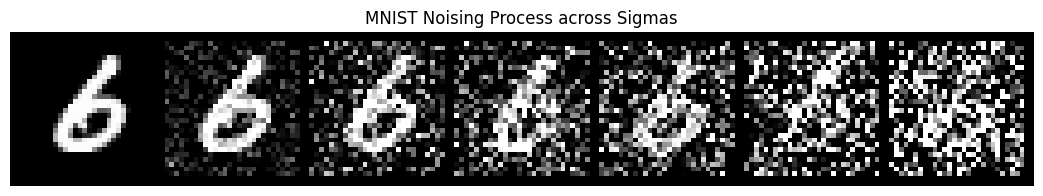

In [43]:
# Visualize images at different noisy level
# ===== your code here! ====
# get a single clean image batch from the dataset
clean_img, _ = next(iter(make_loader(batch_size=1, seed=SEED)))
clean_img = clean_img.to(device)
# the different sigma vals that the unet takes in
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
# store the returned images after changes
noisy_images = []
for sigma in sigmas:
    # add Gaussian noise: x_noisy = x + sigma * z
    z = torch.randn_like(clean_img)
    noisy_img = clean_img + sigma * z
    noisy_images.append(noisy_img)
# now stack all noisy versions into a single batch and plot
noisy_batch = torch.cat(noisy_images, dim=0)
show_grid(noisy_batch, title="MNIST Noising Process across Sigmas", filename="noising_process.png", nrow=len(sigmas))
# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [44]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [45]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = make_loader(batch_size=batch_size, seed=SEED)
test_loader = DataLoader(torch.utils.data.TensorDataset(test_dataset.data[:, None].float() / 255, test_dataset.targets),batch_size=batch_size,shuffle=False)

In [46]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

  0%|          | 0/235 [00:00<?, ?it/s]

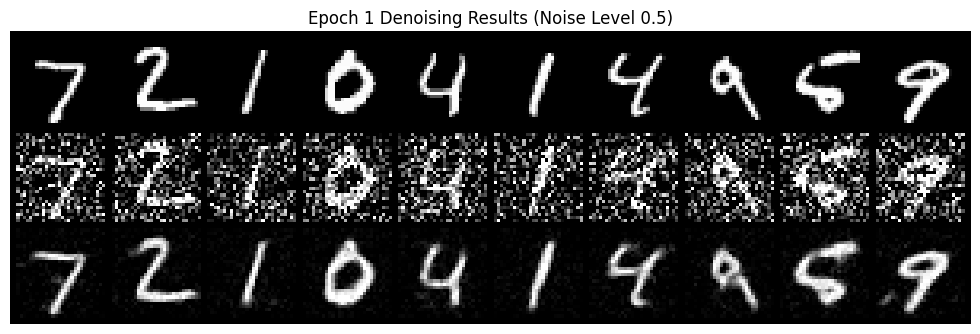

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

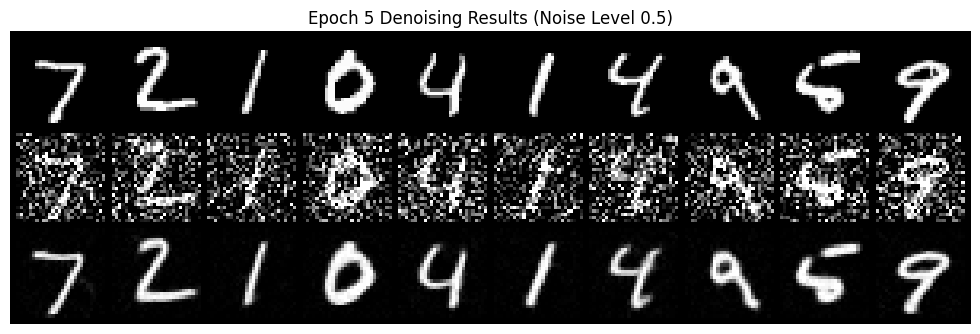

In [47]:
# The training loops
train_losses = []
for epoch in range(num_epochs):
    model.train()
    for i, (images, _) in enumerate(tqdm(train_loader)):
        images = images.to(device)
        # ===== your code here! ====
        # add fresh noise for each batch
        z = torch.randn_like(images)
        noisy_images = images + noise_level * z
        outputs = model(noisy_images)
        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    if epoch == 0 or epoch == num_epochs - 1:
        model.eval()
        with torch.no_grad():
            test_images, _ = next(iter(test_loader))
            test_images = test_images[:10].to(device)
            noisy_test = test_images + noise_level * torch.randn_like(test_images)
            denoised_test = model(noisy_test)

            # stack original, noisy, and denoised for visualization
            vis_grid = torch.cat([test_images, noisy_test, denoised_test], dim=0)
            show_grid(vis_grid, title=f"Epoch {epoch+1} Denoising Results (Noise Level 0.5)", filename=f"denoise_epoch_{epoch+1}.png", nrow=10)

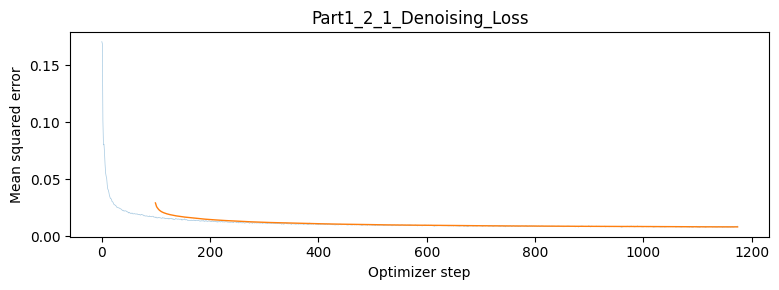

In [48]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "Part1_2_1_Denoising_Loss")
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

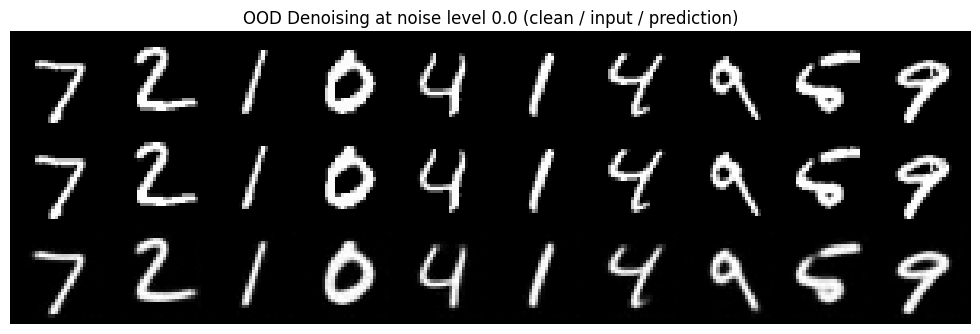

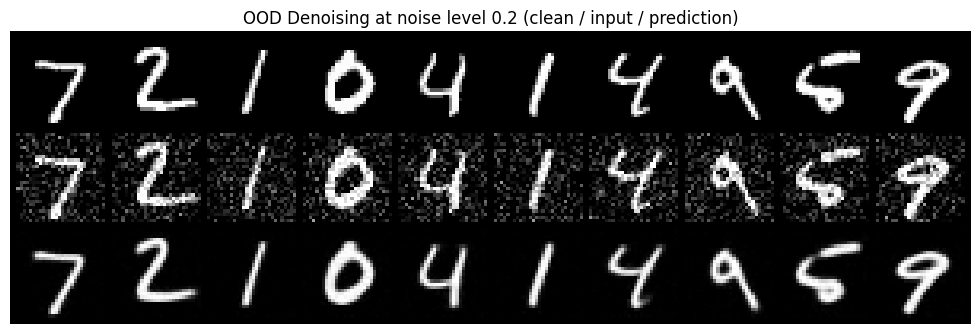

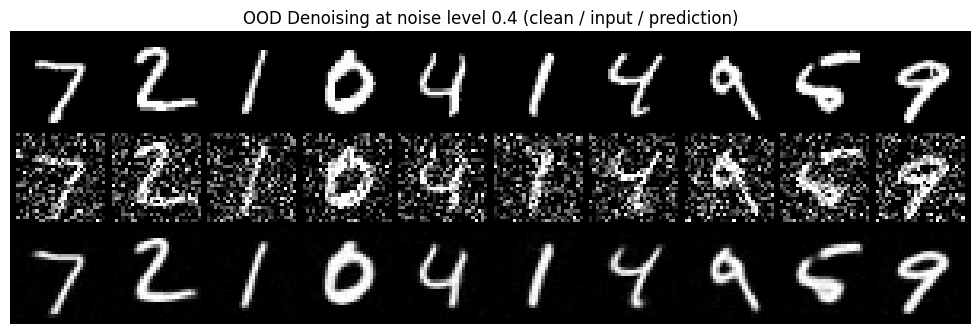

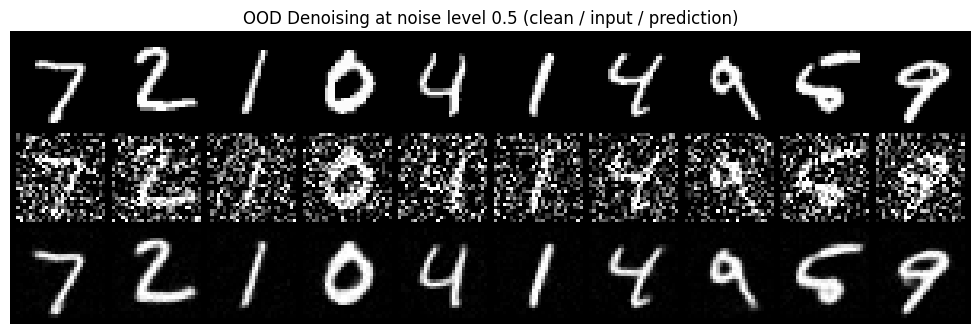

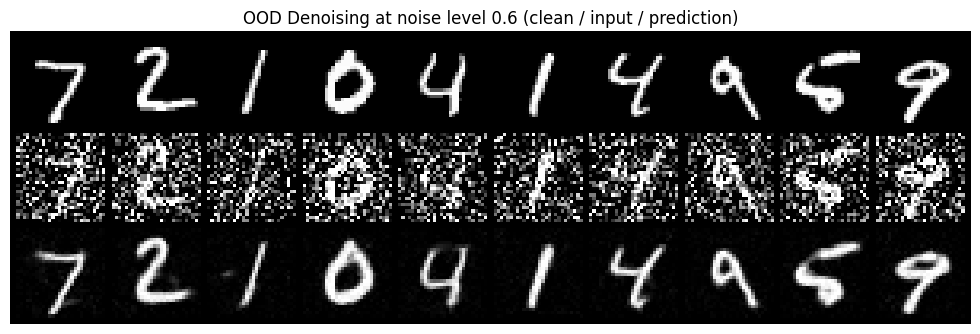

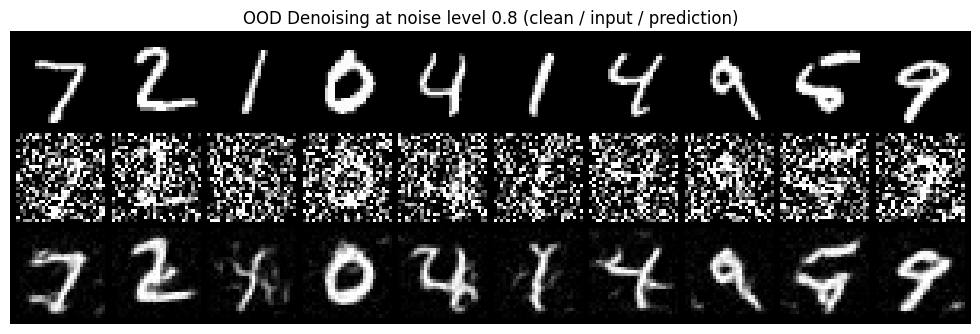

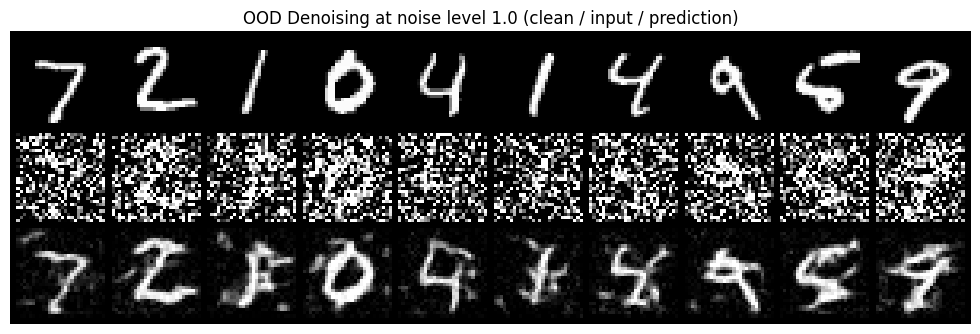

In [52]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
with torch.no_grad():
    # grab 10 images from the test set to use for comparison
    test_images, _ = next(iter(test_loader))
    test_images = test_images[:10].to(device)  # move the images to the device
    # try a few different noise levels, including clean images
    sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
    for sigma in sigmas:
        # add random gaussian noise to the original images
        z = torch.randn_like(test_images)
        noisy_images = test_images + sigma * z
        # let the model try to recover the original images from the noisy ones
        denoised_images = model(noisy_images)
        # put the clean, noisy, and denoised images together for an easier comparison
        # each row shows one type of image, with 10 images in each row
        grid_3x10 = torch.cat([test_images, noisy_images, denoised_images], dim=0)
        # save the results so we can compare how well the model handles each noise level
        show_grid(
            grid_3x10,
            title=f"OOD Denoising at noise level {sigma} (clean / input / prediction)",
            filename=f"ood_denoising_sigma_{sigma}.png",
            nrow=10
        )
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

Pure Noise Epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

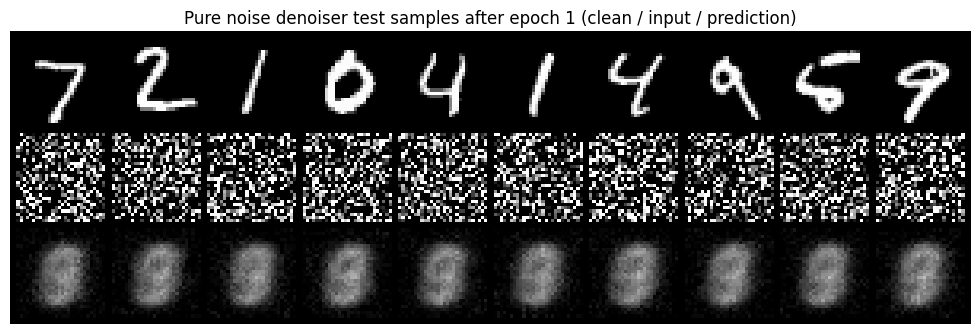

Pure Noise Epoch 2/5:   0%|          | 0/235 [00:00<?, ?it/s]

Pure Noise Epoch 3/5:   0%|          | 0/235 [00:00<?, ?it/s]

Pure Noise Epoch 4/5:   0%|          | 0/235 [00:00<?, ?it/s]

Pure Noise Epoch 5/5:   0%|          | 0/235 [00:00<?, ?it/s]

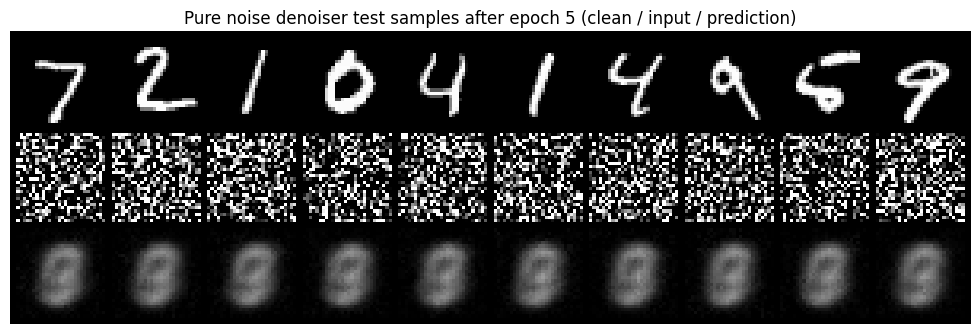

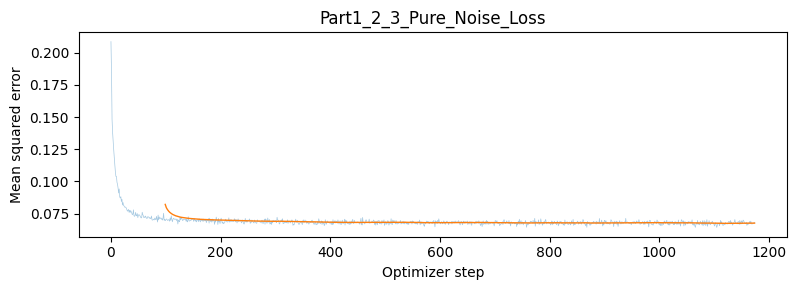

In [55]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.
#raise NotImplementedError('Implement the pure-noise experiment')
# Sample and visualize results at Epoch 1 and Epoch 5
pure_noise_model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
pure_noise_optimizer = torch.optim.Adam(pure_noise_model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# keep track of the loss as the model trains
pure_noise_losses = []
for epoch in range(num_epochs):
    pure_noise_model.train()
    for images, _ in tqdm(train_loader, desc=f"Pure Noise Epoch {epoch+1}/{num_epochs}"):
        images = images.to(device)
        # create random noise with the same shape as the training images
        pure_noise = torch.randn_like(images)
        # see if the model can turn random noise into the original images
        outputs = pure_noise_model(pure_noise)
        # measure how close the predictions are to the real images
        loss = criterion(outputs, images)
        # update the model weights to help it make better predictions
        pure_noise_optimizer.zero_grad()
        loss.backward()
        pure_noise_optimizer.step()
        # save the loss so we can check how training went later
        pure_noise_losses.append(loss.item())
    # check the results after the first and last epochs
    if epoch == 0 or epoch == num_epochs - 1:
        pure_noise_model.eval()
        with torch.no_grad():
            # grab a few test images to compare with the model outputs
            clean_targets, _ = next(iter(test_loader))
            clean_targets = clean_targets[:10].to(device)
            # generate a fresh batch of random noise for testing
            test_noise = torch.randn_like(clean_targets)
            # pass the noise through the model to see what it produces
            predictions = pure_noise_model(test_noise)
            # put the clean images, noise, and predictions together in one grid
            grid_3rows = torch.cat([clean_targets, test_noise, predictions], dim=0)
            # save the grid to compare the results across epochs
            show_grid(
                grid_3rows,
                title=f"Pure noise denoiser test samples after epoch {epoch+1} (clean / input / prediction)",
                filename=f"pure_noise_epoch_{epoch+1}.png",
                nrow=10
            )
# plot the loss curve to see how the model changed during training
loss_plot(pure_noise_losses, "Part1_2_3_Pure_Noise_Loss")


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [68]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.Linear(in_channels, out_channels),nn.GELU(), nn.Linear(out_channels, out_channels),)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        #raise NotImplementedError()


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int = 1,
        num_classes: int = 10,
        num_hiddens: int = 64,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        # FC blocks for embedding
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc2_t = FCBlock(1, D)
        # encoder Path
        self.in_conv = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, 2 * D)
        self.down2 = DownBlock(2 * D, 4 * D)
        # bottleneck
        self.flatten = Flatten()
        self.unflatten = Unflatten(4 * D)
        # decoder Path
        self.up1 = UpBlock(8 * D, 2 * D)
        self.up2 = UpBlock(4 * D, D)
        self.out_conv = nn.Conv2d(2 * D, in_channels, kernel_size=3, stride=1, padding=1)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        if t.ndim == 1:
            t = t.unsqueeze(-1)
        # embed t and unsqueeze spatial dimensions for elementwise multiplication
        t1 = self.fc1_t(t).unsqueeze(-1).unsqueeze(-1)  # Shape: (N, 2D, 1, 1)
        t2 = self.fc2_t(t).unsqueeze(-1).unsqueeze(-1)  # Shape: (N, D, 1, 1)
        # downsample path
        x1 = self.in_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        #bottleneck
        latent = self.flatten(x3)
        bottleneck = self.unflatten(latent)
        # upsample path
        up1_in = torch.cat([bottleneck, x3], dim=1)
        out1 = self.up1(up1_in)
        out1 = out1 * t1
        up2_in = torch.cat([out1, x2], dim=1)
        out2 = self.up2(up2_in)
        # change up1/up2 layer output with t2
        out2 = out2 * t2
        out_in = torch.cat([out2, x1], dim=1)
        out = self.out_conv(out_in)
        return out

        # ===== end of code ====
        #raise NotImplementedError()

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [67]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    batch_size = x_1.shape[0]
    device = x_1.device
    # first sample x_0 ~ N(0, I) pure noise
    x_0 = torch.randn_like(x_1)
    # then sample random continuous time t ~ Uniform(0, 1) per image in batch
    t = torch.rand(batch_size, device=device)
    # then construct x_t = (1 - t) * x_0 + t * x_1
    t_expanded = t.view(batch_size, 1, 1, 1)
    x_t = (1.0 - t_expanded) * x_0 + t_expanded * x_1
    # get flow/Velocity target: v = x_1 - x_0
    target_v = x_1 - x_0
    # now predict flow with time-conditioned UNet
    pred_v = unet(x_t, t)
    # MSE loss
    loss = F.mse_loss(pred_v, target_v)
    return loss

    # ===== end of code ====
    #raise NotImplementedError()

In [66]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    g = torch.Generator(device=unet.in_conv.net[0].net[0].weight.device)
    g.manual_seed(seed)
    # generate 40 samples for visualization grid
    device = unet.in_conv.net[0].net[0].weight.device
    num_samples = 40
    H, W = img_wh
    # start at x_0 ~ N(0, I) pure Gaussian noise at t = 0
    x_t = torch.randn((num_samples, 1, H, W), generator=g, device=device)
    dt = 1.0 / num_ts
    # do euler integration steps from t = 0 to t = 1
    for step in range(num_ts):
        t_val = step * dt
        t_tensor = torch.full((num_samples,), t_val, device=device)
        # predict velocity field
        pred_v = unet(x_t, t_tensor)
        # do euler step
        x_t = x_t + dt * pred_v
    return x_t

    # ===== end of code ====
    #raise NotImplementedError()

In [65]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 4/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 5/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 6/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 7/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 8/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

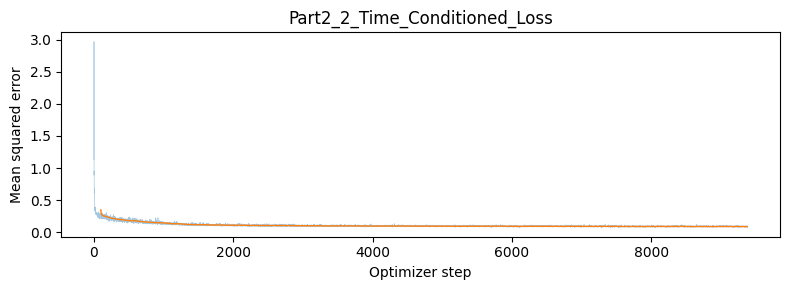

In [76]:
# ===== Section 2.2: Training the Time-Conditioned UNet =====
num_epochs = 10
batch_size = 64
hidden_dim = 64
learning_rate = 1e-2
gamma = 0.1 ** (1.0 / 10.0)  # Exponential lr decay: gamma ≈ 0.794328
#  batch size 64
time_train_loader = make_loader(batch_size=batch_size, seed=SEED)
# setup the model
time_unet = TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim).to(device)
flow_model = TimeConditionalFM(unet=time_unet, num_ts=50).to(device)
# use optimizer
optimizer = torch.optim.Adam(time_unet.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)
# store training losses
train_losses = []
# go through each epoch in total of 10 epochs
epoch_samples = {}
for epoch in range(num_epochs):
    time_unet.train()
    pbar = tqdm(time_train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for images, _ in pbar:
        images = images.to(device)
        # find flow-matching loss
        loss = flow_model(images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # add to train losses lst
        train_losses.append(loss.item())
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
    scheduler.step()
    # create sampling grids at Epochs 1, 5, and 10
    if epoch in [0, 4, 9]:
        epoch_samples[epoch + 1] = flow_model.sample(img_wh=(28, 28), seed=SEED)

# Plot training loss curve over all steps
loss_plot(train_losses, "Part2_2_Time_Conditioned_Loss")

# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

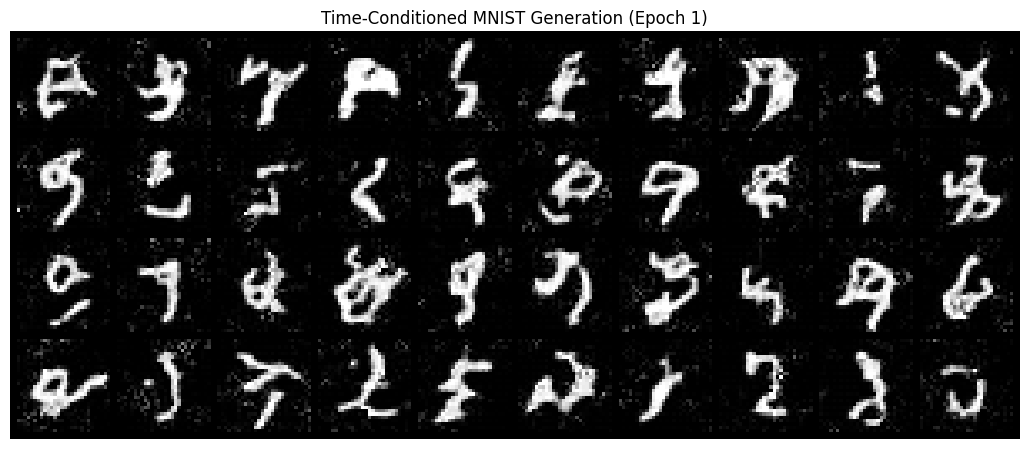

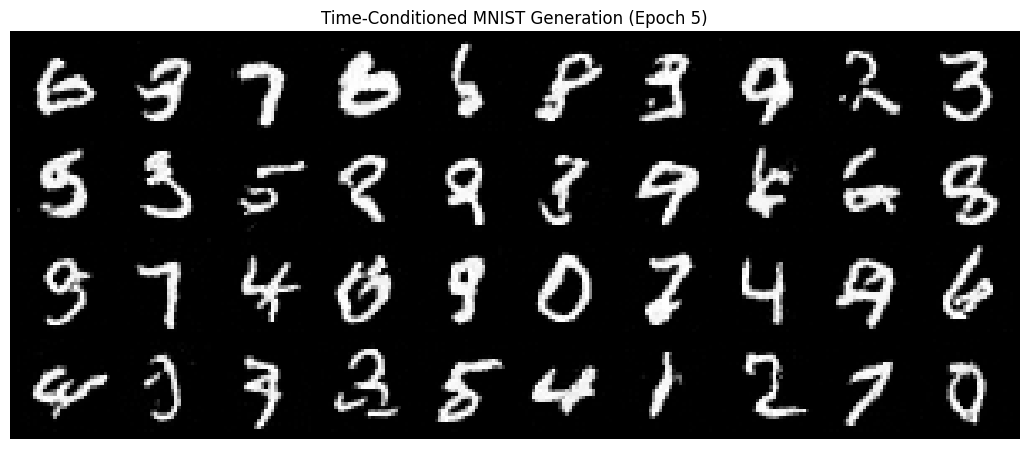

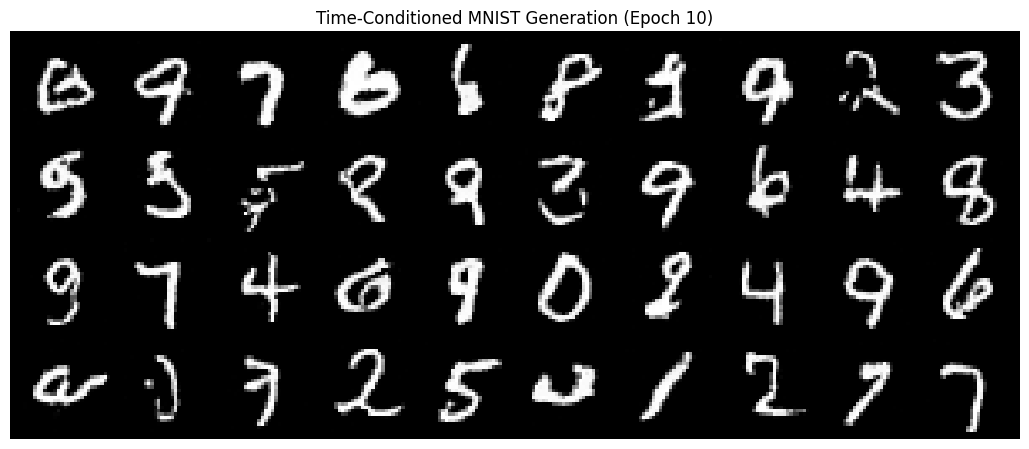

In [77]:
# Sampling from the UNet
# ===== your code here! ====
for epoch_num in [1, 5, 10]:
    sampled_images = epoch_samples[epoch_num]

    show_grid(sampled_images, title=f"Time-Conditioned MNIST Generation (Epoch {epoch_num})", filename=f"time_cond_epoch_{epoch_num}.png", nrow=10)

# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [90]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.num_classes = num_classes
        # fully connected blocks
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc2_t = FCBlock(1, D)
        self.fc1_c = FCBlock(num_classes, 2 * D)
        self.fc2_c = FCBlock(num_classes, D)
        # encoder Path
        self.in_conv = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, 2 * D)
        self.down2 = DownBlock(2 * D, 4 * D)
        # bottleneck
        self.flatten = Flatten()
        self.unflatten = Unflatten(4 * D)
        # decoder Path
        self.up1 = UpBlock(8 * D, 2 * D)
        self.up2 = UpBlock(4 * D, D)
        self.out_conv = nn.Conv2d(2 * D, in_channels, kernel_size=3, stride=1, padding=1)

        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        batch_size = x.shape[0]
        # convert class indices to one-hot vectors if passed as integer labels
        if c.ndim == 1:
            c_onehot = F.one_hot(c, num_classes=self.num_classes).float()
        else:
            c_onehot = c.float()
        # apply mask if there is a mask
        if mask is not None:
            c_onehot = c_onehot * mask.view(-1, 1)
        # reshape t to (N, 1) if provided as (N,)
        if t.ndim == 1:
            t = t.unsqueeze(-1)
        # unsqueeze for spatial modulation
        t1 = self.fc1_t(t).unsqueeze(-1).unsqueeze(-1)
        t2 = self.fc2_t(t).unsqueeze(-1).unsqueeze(-1)
        c1 = self.fc1_c(c_onehot).unsqueeze(-1).unsqueeze(-1)
        c2 = self.fc2_c(c_onehot).unsqueeze(-1).unsqueeze(-1)
        # downsample the path
        x1 = self.in_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        # bottleneck
        latent = self.flatten(x3)
        bottleneck = self.unflatten(latent)
        # decoder path with affine
        up1_in = torch.cat([bottleneck, x3], dim=1)
        out1 = self.up1(up1_in)
        out1 = c1 * out1 + t1
        up2_in = torch.cat([out1, x2], dim=1)
        out2 = self.up2(up2_in)
        out2 = c2 * out2 + t2
        out_in = torch.cat([out2, x1], dim=1)
        out = self.out_conv(out_in)
        return out
        # ===== end of code ====
        #raise NotImplementedError()

In [91]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    batch_size = x_1.shape[0]
    device = x_1.device
    # sample -> pure nosie
    x_0 = torch.randn_like(x_1)
    # sample random continuous time t
    t = torch.rand(batch_size, device=device)
    # linear interpolation
    t_expanded = t.view(batch_size, 1, 1, 1)
    x_t = (1.0 - t_expanded) * x_0 + t_expanded * x_1
    # velocity target
    target_v = x_1 - x_0
    # bernoulli mask
    mask = (torch.rand(batch_size, device=device) >= p_uncond).float()
    #predict velocity
    pred_v = unet(x_t, c, t, mask=mask)
    loss = F.mse_loss(pred_v, target_v)
    return loss

    # ===== end of code ====
    #raise NotImplementedError()

In [89]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    device = next(unet.parameters()).device
    g = torch.Generator(device=device)
    g.manual_seed(seed)
    num_samples = c.shape[0]
    H, W = img_wh
    #initialize x_0
    x_t = torch.randn((num_samples, 1, H, W), generator=g, device=device)
    dt = 1.0 / num_ts
    # create active mask and null mask
    mask_cond = torch.ones(num_samples, device=device)
    mask_uncond = torch.zeros(num_samples, device=device)
    caches = []
    # go theourhg each time step
    for step in range(num_ts):
        t_val = step * dt
        t_tensor = torch.full((num_samples,), t_val, device=device)
        # predict cond velocity
        v_cond = unet(x_t, c, t_tensor, mask=mask_cond)
        # predict uncond velocity
        v_uncond = unet(x_t, c, t_tensor, mask=mask_uncond)
        # CFG
        v_pred = v_uncond + guidance_scale * (v_cond - v_uncond)
        # euler step
        x_t = x_t + dt * v_pred
        caches.append(x_t.cpu())
    caches = torch.stack(caches, dim=1)  # (N, T, C, H, W)
    return x_t, caches

    # ===== end of code ====
    raise NotImplementedError()

In [87]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

Starting Experiment 1: Class-Conditioned UNet with Exponential LR Scheduler...


[Exp Scheduler] Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Exp Scheduler] Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Exp Scheduler] Epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Exp Scheduler] Epoch 4/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

[Constant LR] Epoch 6/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Constant LR] Epoch 7/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Constant LR] Epoch 8/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Constant LR] Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

[Constant LR] Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

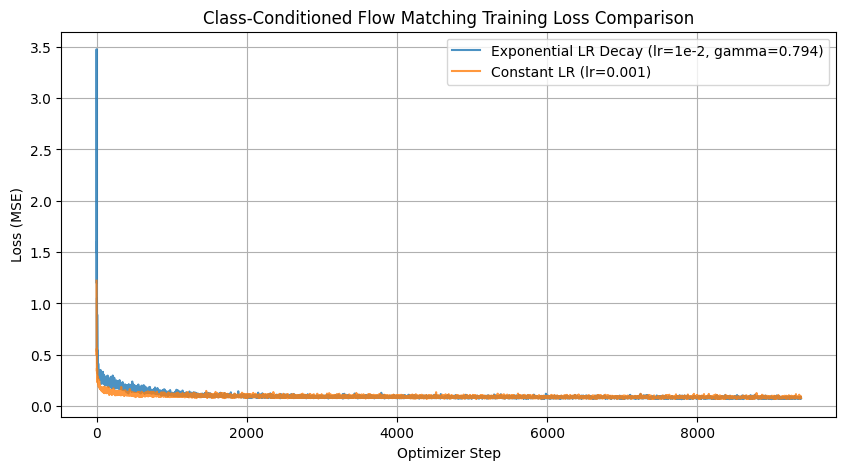

In [98]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.

# set the main training settings
num_epochs = 10
batch_size = 64
hidden_dim = 64
initial_lr = 1e-2
p_uncond = 0.1
num_ts_train = 300
gamma = 0.1 ** (1.0 / 10.0)  # slowly lower the learning rate during training
# use a fixed learning rate for the comparison run
constant_lr = 1e-3
# load the training data in batches
class_train_loader = make_loader(batch_size=batch_size, seed=SEED)
# experiment 1: train with an exponential learning rate scheduler
print("Starting Experiment 1: Class-Conditioned UNet with Exponential LR Scheduler...")
unet_exp = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim).to(device)
flow_model_exp = ClassConditionalFM(unet=unet_exp, num_ts=num_ts_train, p_uncond=p_uncond).to(device)
# set up the optimizer and scheduler for this run
optimizer_exp = torch.optim.Adam(unet_exp.parameters(), lr=initial_lr)
scheduler_exp = torch.optim.lr_scheduler.ExponentialLR(optimizer_exp, gamma=gamma)
# keep the losses and save copies of the model at a few points
losses_exp = []
checkpoints = {}  # keep the model weights from epochs 1, 5, and 10
for epoch in range(num_epochs):
    unet_exp.train()
    pbar = tqdm(class_train_loader, desc=f"[Exp Scheduler] Epoch {epoch+1}/{num_epochs}")
    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)
        # calculate the loss using the images and their class labels
        loss = flow_model_exp(images, labels)
        # update the model based on the loss
        optimizer_exp.zero_grad()
        loss.backward()
        optimizer_exp.step()
        # save the loss and show it while training
        losses_exp.append(loss.item())
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
    # lower the learning rate after each epoch
    scheduler_exp.step()
    # save the model weights so we can compare different training stages later
    if epoch in [0, 4, 9]:
        checkpoints[epoch + 1] = copy.deepcopy(unet_exp.state_dict())
        torch.save(unet_exp.state_dict(), f"class_unet_epoch_{epoch+1}.pt")
# experiment 2: train a separate model with a fixed learning rate
print(f"\nStarting Experiment 2: Constant LR ({constant_lr}) Baseline...")
unet_const = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim).to(device)
flow_model_const = ClassConditionalFM(unet=unet_const, num_ts=num_ts_train, p_uncond=p_uncond).to(device)
# use the same optimizer but keep the learning rate constant
optimizer_const = torch.optim.Adam(unet_const.parameters(), lr=constant_lr)
losses_const = []
for epoch in range(num_epochs):
    unet_const.train()
    pbar = tqdm(class_train_loader, desc=f"[Constant LR] Epoch {epoch+1}/{num_epochs}")
    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)
        # calculate the loss for this batch
        loss = flow_model_const(images, labels)
        # update the model weights
        optimizer_const.zero_grad()
        loss.backward()
        optimizer_const.step()
        # keep track of the loss as the model trains
        losses_const.append(loss.item())
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
# plot both runs to see how the learning rate affects training
plt.figure(figsize=(10, 5))
plt.plot(losses_exp, label="Exponential LR Decay (lr=1e-2, gamma=0.794)", alpha=0.8)
plt.plot(losses_const, label=f"Constant LR (lr={constant_lr})", alpha=0.8)
plt.xlabel("Optimizer Step")
plt.ylabel("Loss (MSE)")
plt.title("Class-Conditioned Flow Matching Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.savefig("Part2_5_Class_Conditioned_Loss_Comparison.png")
plt.show()


# Part 2.6: Sampling from the Class-conditioned UNet

Sampling Epoch 1 (Exponential LR Scheduler)...


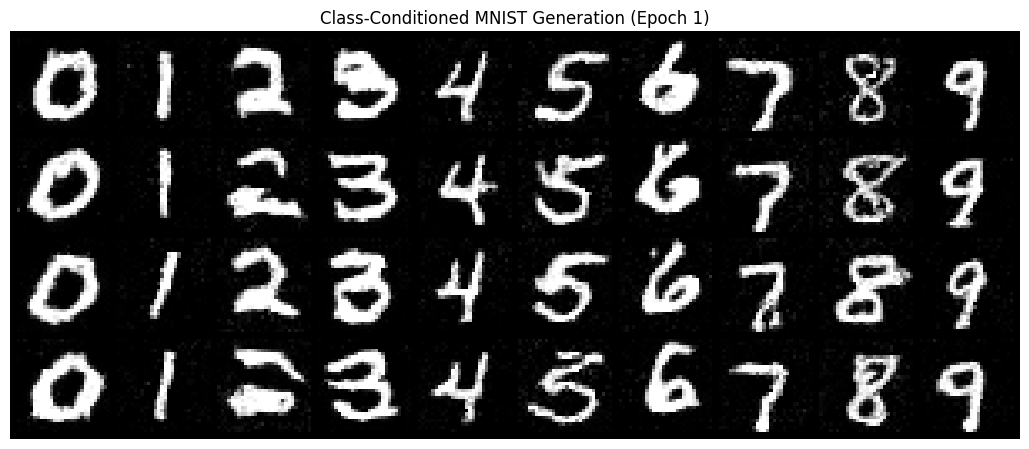

Sampling Epoch 5 (Exponential LR Scheduler)...


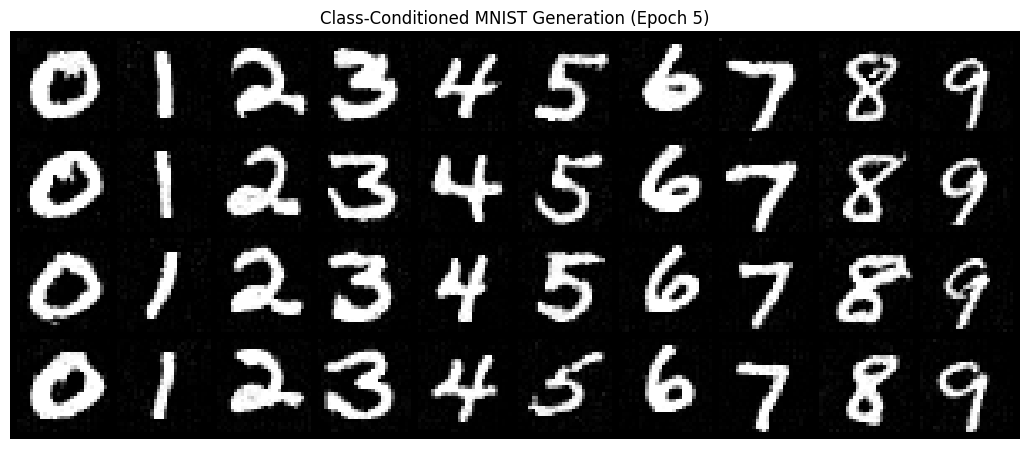

Sampling Epoch 10 (Exponential LR Scheduler)...


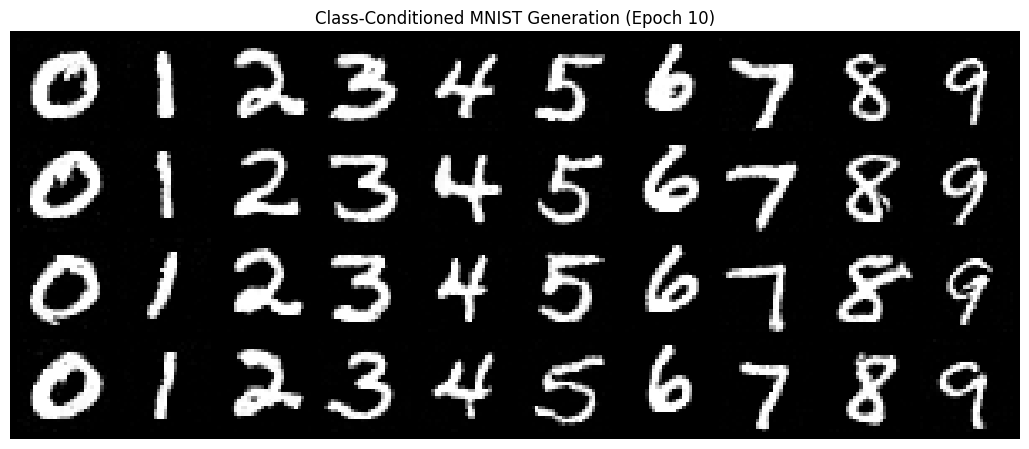


Sampling Constant LR Model (No Scheduler Baseline)...


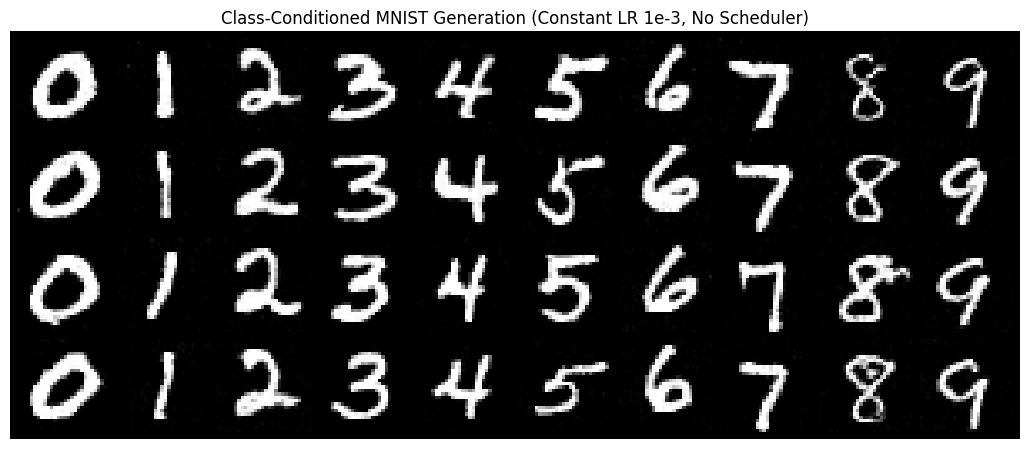

In [99]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
# create four samples for each digit from 0 to 9
c_targets = torch.tensor([digit for _ in range(4) for digit in range(10)], device=device)
# generate samples from the saved models at epochs 1, 5, and 10
for epoch_num in [1, 5, 10]:
    # load the model weights saved during training
    unet_eval = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim).to(device)
    unet_eval.load_state_dict(checkpoints[epoch_num])
    # set up the flow matching model for generating images
    fm_eval = ClassConditionalFM(unet=unet_eval, num_ts=300, p_uncond=p_uncond).to(device)
    print(f"Sampling Epoch {epoch_num} (Exponential LR Scheduler)...")
    # generate digits using the requested labels and guidance scale
    samples, _ = fm_eval.sample(c=c_targets, img_wh=(28, 28), guidance_scale=5.0, seed=SEED)
    # save the generated digits in a grid so we can compare training progress
    show_grid(
        samples,
        title=f"Class-Conditioned MNIST Generation (Epoch {epoch_num})",
        filename=f"class_cond_epoch_{epoch_num}.png",
        nrow=10  # show digits 0 to 9 across each row
    )
# generate samples from the model trained with a constant learning rate
print("\nSampling Constant LR Model (No Scheduler Baseline)...")
fm_const_eval = ClassConditionalFM(unet=unet_const, num_ts=300, p_uncond=p_uncond).to(device)
# use the same labels and guidance scale for a fair comparison
samples_const, _ = fm_const_eval.sample(c=c_targets, img_wh=(28, 28), guidance_scale=5.0, seed=SEED)
# save the final samples to compare against the scheduler results
show_grid(
    samples_const,
    title="Class-Conditioned MNIST Generation (Constant LR 1e-3, No Scheduler)",
    filename="class_cond_no_scheduler_final.png",
    nrow=10
)
